> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


<b>Tarea M-27-CD Proyecto de empresa aliada: entregable 3.</b>

Índice:

Preámbulo.

Objetivo de la tarea.

Importación de librerías.

Carga y conocimiento de los datos.

Preparación y validación de los datos.

Construcción del perfil comercial.

Segmentación mediante K-Means.
   
    Preparación de variables.
   
    Selección del número de clústeres.
   
    Modelo final e interpretación.
   

Validación y análisis complementario.

    Evaluación de la segmentación.
   
    Análisis de atributos categóricos.
   
    Visualización mediante PCA.
   

Recomendaciones y conclusiones.

Resultados finales y exportación.

1. Preámbulo.

Aplicar técnicas de clustering para identificar segmentos clave en los que la marca Vanish tiene presencia, e identificar áreas en las que mejorar su estrategia.

2. Objetivo de la tarea.

Seleccionar las características para el clustering:

- Elige las características clave que se utilizarán para segmentar los productos o regiones. Por ejemplo, puedes basarte en:

- Ventas totales 

- Categoría de producto 

- Región geográfica 

- Atributos específicos de los productos

Estandarizar las características:

- Utiliza un método de escalado, como StandardScaler de Scikit-learn, para estandarizar las características seleccionadas. Esto es crucial, ya que K-Means se ve afectado por las diferentes escalas de los datos. Asegúrate de que todas las variables estén en la misma escala para obtener mejores resultados.

Aplicar el algoritmo K-Means:

- Elige un número inicial de clusters (por ejemplo, 3 o 4) y aplica el algoritmo K-Means usando Scikit-learn.

- Realiza varias iteraciones con diferentes números de clusters para determinar cuál es el óptimo. Puedes utilizar el método del codo para evaluar qué número de clusters minimiza la suma de las distancias al centroide de cada cluster.

Evaluar los resultados del clustering:

- Revisa los resultados obtenidos y asigna cada producto o región a un cluster. Cada cluster debe representar un grupo de productos o regiones con características similares.

- Analiza las características de cada cluster y observa si hay patrones o segmentos que destacan en las ventas, categoría o región.

Visualizar los clusters:

- Crea gráficos de dispersión utilizando Matplotlib o Seaborn para visualizar cómo los productos o regiones se agrupan en función de las características seleccionadas. Usa colores para diferenciar los clusters y añade etiquetas para identificar los productos o regiones clave dentro de cada uno.

- Genera gráficos adicionales, como gráficos de barras o diagramas de caja, para explorar más a fondo los resultados del clustering.

Interpretar y analizar los clusters:

- Documenta los insights clave de los resultados. Por ejemplo, ¿hay segmentos donde la marca Vanish tiene un fuerte desempeño? ¿Qué clusters muestran un rendimiento bajo o áreas de mejora?

- Identifica si existen patrones en los productos o regiones que puedan influir en la estrategia comercial. Por ejemplo, si un cluster contiene productos con ventas bajas, ¿hay alguna característica en común que podría explicar ese desempeño?

Entregables solicitados.

- Guarda los resultados del clustering (incluyendo la asignación de clusters a productos o regiones) en un nuevo DataFrame o archivo CSV.

3. Importación de librerías.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

4. Carga y conocimiento inicial de los datos.

In [2]:
import pandas as pd
dim_calendar = pd.read_excel("DIM_CALENDAR (2).xlsx")
dim_category = pd.read_csv("DIM_CATEGORY (2).csv")
dim_segment = pd.read_excel("DIM_SEGMENT (1).xlsx")
dim_product = pd.read_excel("DIM_PRODUCT (1).xlsx")
fact_sales = pd.read_csv("FACT_SALES (1).csv")

In [3]:
tablas = {"DIM_CALENDAR": dim_calendar,"DIM_CATEGORY": dim_category,
    "DIM_SEGMENT": dim_segment, "DIM_PRODUCT": dim_product, "FACT_SALES": fact_sales}

for nombre, df in tablas.items():
    print(f"\n{nombre}")
    print(f"Dimensiones: {df.shape}")
    print("Columnas:", df.columns.tolist())
    display(df.head())


DIM_CALENDAR
Dimensiones: (156, 5)
Columnas: ['WEEK', 'YEAR', 'MONTH', 'WEEK_NUMBER', 'DATE']


,WEEK,YEAR,MONTH,WEEK_NUMBER,DATE
0,01-21,2021,1,1,2021-01-10
1,02-21,2021,1,2,2021-01-17
2,03-21,2021,1,3,2021-01-24
3,04-21,2021,1,4,2021-01-31
4,05-21,2021,2,5,2021-02-07



DIM_CATEGORY
Dimensiones: (5, 2)
Columnas: ['ID_CATEGORY', 'CATEGORY']


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC



DIM_SEGMENT
Dimensiones: (53, 6)
Columnas: ['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT']


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH



DIM_PRODUCT
Dimensiones: (505, 9)
Columnas: ['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3']


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO



FACT_SALES
Dimensiones: (122002, 6)
Columnas: ['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION']


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5


In [4]:
# Validación tipos de datos, nulos, duplicados y llaves únicas.

for nombre, df in tablas.items():
    print(f"\n{'=' * 50}")
    print(nombre)
    print(f"{'=' * 50}")

    print("\nTipos de datos:")
    print(df.dtypes)

    print("\nValores nulos:")
    print(df.isna().sum())

    print("\nFilas duplicadas:", df.duplicated().sum())


DIM_CALENDAR

Tipos de datos:
WEEK                   object
YEAR                    int64
MONTH                   int64
WEEK_NUMBER             int64
DATE           datetime64[ns]
dtype: object

Valores nulos:
WEEK           0
YEAR           0
MONTH          0
WEEK_NUMBER    0
DATE           0
dtype: int64

Filas duplicadas: 0

DIM_CATEGORY

Tipos de datos:
ID_CATEGORY     int64
CATEGORY       object
dtype: object

Valores nulos:
ID_CATEGORY    0
CATEGORY       0
dtype: int64

Filas duplicadas: 0

DIM_SEGMENT

Tipos de datos:
CATEGORY     int64
ATTR1       object
ATTR2       object
ATTR3       object
FORMAT      object
SEGMENT     object
dtype: object

Valores nulos:
CATEGORY    0
ATTR1       0
ATTR2       0
ATTR3       1
FORMAT      0
SEGMENT     0
dtype: int64

Filas duplicadas: 0

DIM_PRODUCT

Tipos de datos:
MANUFACTURER        object
BRAND               object
ITEM                object
ITEM_DESCRIPTION    object
CATEGORY             int64
FORMAT              object
ATTR1        

## 5. Validación y preparación de los datos.

In [5]:
# Verificación de registros completos y determinar su origen.

print("Filas con algún nulo en DIM_SEGMENT:")
display(dim_segment[dim_segment.isna().any(axis=1)])

print("\nFilas con algún nulo en DIM_PRODUCT:")
display(dim_product[dim_product.isna().any(axis=1)])

Filas con algún nulo en DIM_SEGMENT:


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
10,1,CLORO,CLORO,NaN,LIQUIDO,BLEACH



Filas con algún nulo en DIM_PRODUCT:


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
33,WHITE MAGIC,WHITE MAGIC,0079893431208,9WHITE MAGIC BOT.PLAS 3970ML IMP 0079893431208,1,LIQUIDO,NaN,CLORO,NaN
107,INDS. ALEN,CLORALEX,7501025401023,CLORALEX EXTRA SENSACION FRUTALES BOT PLAST 95...,1,LIQUIDO,NaN,CLORO,NaN
143,INDS. ALEN,BLANCATEL,7501025402259,BLANCATEL BLANQUEADOR BOTELLA 1.8LT 7501025402259,1,LIQUIDO,NaN,CLORO,NaN
343,CLOROX,CLOROX,7501071901591,CLOROX BLANQUEADOR PARAISO TROPICAL 3800 ML NA...,1,LIQUIDO,NaN,CLORO,NaN
469,OTHERS FABRICANTE UNIF.,OTHERS MARCA UNIF.,7502217411776,KLEEN CLORO BOTELLA 1000 ML NAL 7502217411776,1,LIQUIDO,NaN,CLORO,NaN
495,IBERIA,IBERIA,8411660040503,9IBERIA BLANQUEADOR POLVO 250 GR IMP 841166004...,1,POLVO,NaN,CLORO,NaN
502,INDS. ALEN,CLORALEX,NaN,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,NaN,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [6]:
# Verificación si las llaves son únicas.

print("WEEK únicas en DIM_CALENDAR:", dim_calendar["WEEK"].is_unique)

print("ID_CATEGORY únicas en DIM_CATEGORY:", dim_category["ID_CATEGORY"].is_unique)

print("ITEM únicos en DIM_PRODUCT, excluyendo nulos:", dim_product["ITEM"].dropna().is_unique)

print("\nITEM duplicados:")
display(dim_product[dim_product["ITEM"].notna() & dim_product["ITEM"].duplicated(keep=False)
    ].sort_values("ITEM"))

WEEK únicas en DIM_CALENDAR: True
ID_CATEGORY únicas en DIM_CATEGORY: True
ITEM únicos en DIM_PRODUCT, excluyendo nulos: True

ITEM duplicados:


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3


La evidencia confirma tres puntos:

- WEEK, ID_CATEGORY e ITEM —excluyendo nulos— son llaves únicas.

- No existen códigos ITEM duplicados.

- Los nulos en ATTR1 y ATTR3 parecen indicar que el atributo no aplica, no necesariamente un error.

- Los registros 502 y 503 no tienen ITEM; por tanto, no pueden relacionarse directamente con FACT_SALES.

In [7]:
# Validar la cobertura de las relaciones.

items_ventas = set(fact_sales["ITEM_CODE"].dropna())
items_catalogo = set(dim_product["ITEM"].dropna())

weeks_ventas = set(fact_sales["WEEK"].dropna())
weeks_calendario = set(dim_calendar["WEEK"].dropna())

print("ITEM_CODE de ventas sin producto asociado:",
      len(items_ventas - items_catalogo))

print("ITEM del catálogo sin ventas:",
      len(items_catalogo - items_ventas))

print("WEEK de ventas sin calendario asociado:",
      len(weeks_ventas - weeks_calendario))

print("\nCódigos de venta sin producto:")
print(sorted(items_ventas - items_catalogo))

ITEM_CODE de ventas sin producto asociado: 0
ITEM del catálogo sin ventas: 153
WEEK de ventas sin calendario asociado: 0

Códigos de venta sin producto:
[]


<b>Conclusión</b>

- Todas las ventas tienen un producto asociado.
- Todas las semanas de ventas existen en el calendario.
- Los 153 productos del catálogo sin ventas no son un error: simplemente no tuvieron movimiento durante el periodo analizado.
- Los dos registros sin ITEM no afectan las ventas, porque ninguna operación depende de ellos.

In [8]:
# Catálogo con llave válida.

dim_product_valido = dim_product.dropna(subset=["ITEM"]).copy()

# Normalización de las llaves como texto.
dim_product_valido["ITEM"] = (dim_product_valido["ITEM"]
    .astype(str).str.strip().str.replace(r"\.0$", "", regex=True))

fact_sales["ITEM_CODE"] = (fact_sales["ITEM_CODE"].astype(str)
    .str.strip().str.replace(r"\.0$", "", regex=True))

# Verificación de cobertura después de normalizar.
items_ventas = set(fact_sales["ITEM_CODE"])
items_catalogo = set(dim_product_valido["ITEM"])

print("ITEM_CODE de ventas sin producto asociado:",
      len(items_ventas - items_catalogo))

print("Ejemplos sin producto asociado:",
      sorted(items_ventas - items_catalogo)[:10])

ITEM_CODE de ventas sin producto asociado: 0
Ejemplos sin producto asociado: []


6. Construcción del perfil comercial por producto.

In [9]:
# Unión de ventas con el catálogo de productos.

ventas_completas = fact_sales.merge(dim_product_valido, how="left", left_on="ITEM_CODE", right_on="ITEM",
    validate="many_to_one")

# Unión con el calendario.

ventas_completas = ventas_completas.merge(dim_calendar, how="left", on="WEEK", validate="many_to_one")

print("Dimensiones originales:", fact_sales.shape)
print("Dimensiones después de las uniones:", ventas_completas.shape)
print("\nNulos en variables principales:")
print(ventas_completas[["ITEM_CODE", "WEEK", "BRAND", "ITEM_DESCRIPTION", "YEAR", "MONTH"]].isna().sum())

display(ventas_completas.head())

Dimensiones originales: (122002, 6)
Dimensiones después de las uniones: (122002, 19)

Nulos en variables principales:
ITEM_CODE           0
WEEK                0
BRAND               0
ITEM_DESCRIPTION    0
YEAR                0
MONTH               0
dtype: int64


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28


In [10]:
print("Columnas de ventas_completas:")
print(ventas_completas.columns.tolist())

Columnas de ventas_completas:
['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3', 'YEAR', 'MONTH', 'WEEK_NUMBER', 'DATE']


In [11]:
columnas_validacion = ["ITEM_CODE", "WEEK", "BRAND", "ITEM_DESCRIPTION", "REGION", "YEAR", "MONTH", "DATE"]

print("Dimensiones originales:", fact_sales.shape)
print("Dimensiones después de las uniones:", ventas_completas.shape)

print("\nNulos en variables principales:")
print(ventas_completas[columnas_validacion].isna().sum())

print("\nRegiones disponibles:")
print(ventas_completas["REGION"].value_counts(dropna=False))

display(ventas_completas.head())

Dimensiones originales: (122002, 6)
Dimensiones después de las uniones: (122002, 19)

Nulos en variables principales:
ITEM_CODE           0
WEEK                0
BRAND               0
ITEM_DESCRIPTION    0
REGION              0
YEAR                0
MONTH               0
DATE                0
dtype: int64

Regiones disponibles:
REGION
TOTAL AUTOS SCANNING MEXICO    20990
TOTAL AUTOS AREA 2             18505
TOTAL AUTOS AREA 4             17182
TOTAL AUTOS AREA 6             16913
TOTAL AUTOS AREA 3             16496
TOTAL AUTOS AREA 5             16135
TOTAL AUTOS AREA 1             15781
Name: count, dtype: int64


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,2022-08-28


In [12]:
# Se nombran columnas para verificar si "TOTAL AUTOS SCANNING MEXICO" es el resultado de la suma de las otras.

metricas = ["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]

region_nacional = "TOTAL AUTOS SCANNING MEXICO"

# Registros del total nacional.

ventas_nacional = (ventas_completas[ventas_completas["REGION"] == region_nacional]
    .groupby(["WEEK", "ITEM_CODE"], as_index=False)[metricas].sum())

# Suma de las seis áreas.

ventas_areas = (ventas_completas[ventas_completas["REGION"] != region_nacional]
    .groupby(["WEEK", "ITEM_CODE"], as_index=False)[metricas].sum())

# Comparación entre total nacional y suma regional.

comparacion_regiones = ventas_nacional.merge(ventas_areas, on=["WEEK", "ITEM_CODE"], how="outer", 
                                             suffixes=("_NACIONAL", "_AREAS"), indicator=True)

for metrica in metricas:
    comparacion_regiones[f"COINCIDE_{metrica}"] = np.isclose(
        comparacion_regiones[f"{metrica}_NACIONAL"],
        comparacion_regiones[f"{metrica}_AREAS"],
        rtol=1e-5, atol=1e-5, equal_nan=False)

print("Cobertura de registros:")
print(comparacion_regiones["_merge"].value_counts())

print("\nCoincidencia de ventas en unidades:")
print(comparacion_regiones["COINCIDE_TOTAL_UNIT_SALES"].value_counts(dropna=False))

print("\nCoincidencia de ventas en valor:")
print(comparacion_regiones["COINCIDE_TOTAL_VALUE_SALES"].value_counts(dropna=False))

display(comparacion_regiones.head())

Cobertura de registros:
_merge
both          20990
left_only         0
right_only        0
Name: count, dtype: int64

Coincidencia de ventas en unidades:
COINCIDE_TOTAL_UNIT_SALES
True     19297
False     1693
Name: count, dtype: int64

Coincidencia de ventas en valor:
COINCIDE_TOTAL_VALUE_SALES
True     16968
False     4022
Name: count, dtype: int64


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES_NACIONAL,TOTAL_VALUE_SALES_NACIONAL,TOTAL_UNIT_SALES_AREAS,TOTAL_VALUE_SALES_AREAS,_merge,COINCIDE_TOTAL_UNIT_SALES,COINCIDE_TOTAL_VALUE_SALES
0,01-22,0000075000592,0.435,1.957,0.435,1.958,both,True,False
1,01-22,0000075000608,12.399,106.325,12.399,106.324,both,True,True
2,01-22,0000075000615,275.542,3795.391,275.541,3795.392,both,True,True
3,01-22,0000075000622,371.038,8393.597,371.038,8393.597,both,True,True
4,01-22,0000075000639,183.329,7390.208,183.329,7390.207,both,True,True


<b>Conclusión.</b>

- Las 20,990 combinaciones de semana y producto aparecen tanto en el total nacional como en la suma de las áreas.
- No hay registros exclusivos de alguna fuente.
- Las diferencias visibles son mínimas y parecen responder al redondeo de los valores regionales, no a ventas faltantes.
- np.isclose() está usando una tolerancia demasiado estricta (0.00001) para datos comerciales expresados con tres decimales.

In [13]:
# Diferencias absolutas entre el total nacional y la suma de áreas.

comparacion_regiones["DIF_UNIDADES"] = abs(comparacion_regiones["TOTAL_UNIT_SALES_NACIONAL"] -
    comparacion_regiones["TOTAL_UNIT_SALES_AREAS"])

comparacion_regiones["DIF_VALOR"] = abs(comparacion_regiones["TOTAL_VALUE_SALES_NACIONAL"] -
    comparacion_regiones["TOTAL_VALUE_SALES_AREAS"])

print("Resumen de diferencias en unidades:")
display(comparacion_regiones["DIF_UNIDADES"].describe())

print("\nResumen de diferencias en valor:")
display(comparacion_regiones["DIF_VALOR"].describe())

print("\nMáximas diferencias observadas:")
display(comparacion_regiones[["WEEK", "ITEM_CODE", "DIF_UNIDADES", "DIF_VALOR"]]
    .sort_values(["DIF_VALOR", "DIF_UNIDADES"], ascending=False).head(10))

Resumen de diferencias en unidades:


count    20990.000000
mean         0.000087
std          0.000287
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.002000
Name: DIF_UNIDADES, dtype: float64


Resumen de diferencias en valor:


count    20990.000000
mean         0.000411
std          0.000540
min          0.000000
25%          0.000000
50%          0.000000
75%          0.001000
max          0.002000
Name: DIF_VALOR, dtype: float64


Máximas diferencias observadas:


,WEEK,ITEM_CODE,DIF_UNIDADES,DIF_VALOR
8023,16-22,7501025402051,1.421085e-14,0.002
2113,05-22,0000075000615,0.000000e+00,0.002
8481,17-22,0000075000622,0.000000e+00,0.002
8760,17-23,0000075000639,0.000000e+00,0.002
18695,44-22,0000075000639,0.000000e+00,0.002
390,01-23,7501058717023,7.105427e-15,0.002
3308,07-22,7501058717023,7.105427e-15,0.002
6494,13-22,7501058717023,0.000000e+00,0.002
9615,19-22,7501025405212,0.000000e+00,0.002
14064,27-23,7501025450212,0.000000e+00,0.002


In [14]:
region_nacional = "TOTAL AUTOS SCANNING MEXICO"

# Base nacional: destinada al clustering de productos.

ventas_nacionales = ventas_completas[ventas_completas["REGION"] == region_nacional].copy()

# Base regional: destinada al análisis geográfico posterior.

ventas_regionales = ventas_completas[ventas_completas["REGION"] != region_nacional].copy()

print("Registros nacionales:", ventas_nacionales.shape[0])
print("Registros regionales:", ventas_regionales.shape[0])

print("\nMarcas relacionadas con Vanish:")
print(ventas_nacionales.loc[ventas_nacionales["BRAND"].astype(str).str.contains("VANISH", case=False, na=False),
        "BRAND"].value_counts())

Registros nacionales: 20990
Registros regionales: 101012

Marcas relacionadas con Vanish:
BRAND
VANISH    4751
Name: count, dtype: int64


In [15]:
# Se realiza filtrado de productos Vanish.

# Ventas nacionales de Vanish.

vanish_nacional = ventas_nacionales[ventas_nacionales["BRAND"] == "VANISH"].copy()

print("Registros nacionales de Vanish:", vanish_nacional.shape[0])
print("Productos Vanish con ventas:", vanish_nacional["ITEM_CODE"].nunique())
print("Semanas analizadas:", vanish_nacional["WEEK"].nunique())

print("\nPeriodo analizado:")
print("Desde:", vanish_nacional["DATE"].min())
print("Hasta:", vanish_nacional["DATE"].max())

print("\nRegistros por producto:")
display(vanish_nacional.groupby(["ITEM_CODE", "ITEM_DESCRIPTION"]).size().describe())

Registros nacionales de Vanish: 4751
Productos Vanish con ventas: 77
Semanas analizadas: 80

Periodo analizado:
Desde: 2022-01-09 00:00:00
Hasta: 2023-07-17 00:00:00

Registros por producto:


count    77.000000
mean     61.701299
std      28.000970
min       1.000000
25%      42.000000
50%      80.000000
75%      80.000000
max      80.000000
dtype: float64

Nota:

La revisión confirma un punto crítico: los productos no tienen la misma cobertura temporal.

- 77 productos Vanish con ventas.
- 80 semanas disponibles.
- Mediana: 80 semanas.
- 25 % de los productos aparece en 42 semanas o menos.
- Mínimo: 1 semana.
- Promedio: 61.7 semanas.

Esto significa que las ventas totales pueden penalizar productos nuevos, descontinuados o con presencia intermitente. No podemos interpretar automáticamente una venta total baja como bajo desempeño.

In [16]:
#Identificación de productos con menor cobertura.

cobertura_productos = (vanish_nacional.groupby(["ITEM_CODE", "ITEM_DESCRIPTION"],as_index=False)
    .agg(SEMANAS_CON_VENTAS=("WEEK", "nunique"), PRIMERA_FECHA=("DATE", "min"), ULTIMA_FECHA=("DATE", "max"),
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"), VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum")))

cobertura_productos["PORCENTAJE_COBERTURA"] = (cobertura_productos["SEMANAS_CON_VENTAS"] / vanish_nacional["WEEK"].nunique() * 100)

print("Distribución de semanas con ventas:")
print(cobertura_productos["SEMANAS_CON_VENTAS"].value_counts().sort_index())

print("\nProductos con menor cobertura:")
display(cobertura_productos.sort_values(["SEMANAS_CON_VENTAS", "PRIMERA_FECHA"]).head(15))

Distribución de semanas con ventas:
SEMANAS_CON_VENTAS
1      3
2      1
4      1
7      1
9      2
12     2
13     1
18     1
26     2
28     2
32     1
35     1
38     1
42     1
45     1
55     1
62     2
66     1
67     1
73     1
74     2
76     2
79     3
80    43
Name: count, dtype: int64

Productos con menor cobertura:


,ITEM_CODE,ITEM_DESCRIPTION,SEMANAS_CON_VENTAS,PRIMERA_FECHA,ULTIMA_FECHA,VENTAS_UNIDADES,VENTAS_VALOR,PORCENTAJE_COBERTURA
44,7501058784889,VANISH MAX 3 BOT 925ML C /U=2775ML LLEVA 3 PAG...,1,2022-09-11,2022-09-11,0.001,0.053,1.25
47,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,2023-04-10,2023-04-10,0.001,0.090,1.25
17,7501058716446,VANISH OXI ACTION CRISTAL WHITE AHORRO DEL 25%...,1,2023-06-26,2023-06-26,0.001,0.007,1.25
41,7501058782694BP1,VANISH OXI ACTION QUITAMANCHAS BOT 450G C/GMM ...,2,2022-02-20,2022-06-26,0.007,0.086,2.50
16,7501058716439,VANISH OXI ACTION GOLD QUITAMANCHAS AHORRO DEL...,4,2022-02-27,2022-06-19,0.000,0.035,5.00
53,7501058793898,VANISH ROSA MULTIUSOS REMOVEDOR MANC 3X2 BOT 9...,7,2022-02-13,2023-03-20,0.011,0.555,8.75
4,7501058715029,VANISH MULTIUSOS REMOVEDOR S/CLORO DE MANCHAS ...,9,2022-01-09,2022-04-24,0.046,0.892,11.25
46,7501058788931,VANISH MULTIUSOS DUOPACK ROSA QUITA MANCHAS 2B...,9,2022-01-23,2022-06-05,0.031,1.264,11.25
5,7501058715036,VANISH WHITE QUITAMANCHAS Y BLANQ.S/CLORO DOYP...,12,2022-01-09,2022-06-26,0.030,0.603,15.00
31,7501058753205,VANISH EXTRA-HIGIENE BOTELLA PLASTICO 900 ML 7...,12,2022-02-13,2023-05-08,0.017,0.421,15.00


In [17]:
# Revisión de caracteríticas de cada producto Vanish.

perfil_productos = (vanish_nacional.groupby(
        ["ITEM_CODE", "ITEM_DESCRIPTION", "CATEGORY", "FORMAT", "ATTR1", "ATTR2", "ATTR3"],
        dropna=False, as_index=False).agg(VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum"), SEMANAS_CON_VENTAS=("WEEK", "nunique"),
        PRIMERA_FECHA=("DATE", "min"), ULTIMA_FECHA=("DATE", "max")))

# Intensidad comercial durante las semanas activas.

perfil_productos["UNIDADES_PROMEDIO_SEMANA"] = (perfil_productos["VENTAS_UNIDADES"] / perfil_productos["SEMANAS_CON_VENTAS"])

perfil_productos["VALOR_PROMEDIO_SEMANA"] = (perfil_productos["VENTAS_VALOR"] /    perfil_productos["SEMANAS_CON_VENTAS"])

# Precio promedio implícito.

perfil_productos["PRECIO_IMPLICITO"] = np.where(perfil_productos["VENTAS_UNIDADES"] > 0, perfil_productos["VENTAS_VALOR"] /
    perfil_productos["VENTAS_UNIDADES"], np.nan)

print("Dimensiones del perfil:", perfil_productos.shape)
print("Productos únicos:", perfil_productos["ITEM_CODE"].nunique())

print("\nNulos en las variables cuantitativas:")
print(perfil_productos[["VENTAS_UNIDADES", "VENTAS_VALOR", "SEMANAS_CON_VENTAS",
            "UNIDADES_PROMEDIO_SEMANA", "VALOR_PROMEDIO_SEMANA", "PRECIO_IMPLICITO"]].isna().sum())

display(perfil_productos.head())

Dimensiones del perfil: (77, 15)
Productos únicos: 77

Nulos en las variables cuantitativas:
VENTAS_UNIDADES             0
VENTAS_VALOR                0
SEMANAS_CON_VENTAS          0
UNIDADES_PROMEDIO_SEMANA    0
VALOR_PROMEDIO_SEMANA       0
PRECIO_IMPLICITO            1
dtype: int64


,ITEM_CODE,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,VENTAS_UNIDADES,VENTAS_VALOR,SEMANAS_CON_VENTAS,PRIMERA_FECHA,ULTIMA_FECHA,UNIDADES_PROMEDIO_SEMANA,VALOR_PROMEDIO_SEMANA,PRECIO_IMPLICITO
0,7501058712813,VANISH OXI ACTION QUITAMANCHAS P/ROPA BOTE 240...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,0.293,14.442,55,2022-01-09,2023-05-22,0.005327,0.262582,49.290102
1,7501058713780,VANISH OXI ACTION ROSA QUITA MANCHAS PARA LA R...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,0.081,1.789,35,2022-01-09,2023-05-29,0.002314,0.051114,22.086420
2,7501058714596,VANISH SUPER BARRA QUITA MANCHAS 68GR 75010587...,1,BARRA,SAFE BLEACH,FABRIC TREATMENT,ROSA,4029.997,49741.969,80,2022-01-09,2023-07-17,50.374962,621.774612,12.342930
3,7501058715012,VANISH OXI ACTION CRISTAL WHITE BOT 150GR 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,BLANCO,0.059,1.551,26,2022-01-09,2023-05-29,0.002269,0.059654,26.288136
4,7501058715029,VANISH MULTIUSOS REMOVEDOR S/CLORO DE MANCHAS ...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,0.046,0.892,9,2022-01-09,2022-04-24,0.005111,0.099111,19.391304


Nota:

El valor nulo fue creado como condición: 
- Algún producto tiene VENTAS_UNIDADES <= 0.

A continuación se identifica y revisa si corresponde a devoluciones, ajustes o ventas netas iguales a cero.

In [18]:
print("Producto con PRECIO_IMPLICITO nulo:")
display(perfil_productos.loc[perfil_productos["PRECIO_IMPLICITO"].isna(),
        ["ITEM_CODE", "ITEM_DESCRIPTION", "FORMAT", "VENTAS_UNIDADES", "VENTAS_VALOR",
            "SEMANAS_CON_VENTAS", "PRIMERA_FECHA","ULTIMA_FECHA"]])

print("\nRegistros semanales del producto:")
item_revisar = perfil_productos.loc[perfil_productos["PRECIO_IMPLICITO"].isna(), "ITEM_CODE"].iloc[0]

display(vanish_nacional.loc[vanish_nacional["ITEM_CODE"] == item_revisar,
        ["WEEK", "DATE", "TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]].sort_values("DATE"))

Producto con PRECIO_IMPLICITO nulo:


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,VENTAS_UNIDADES,VENTAS_VALOR,SEMANAS_CON_VENTAS,PRIMERA_FECHA,ULTIMA_FECHA
16,7501058716439,VANISH OXI ACTION GOLD QUITAMANCHAS AHORRO DEL...,POLVO,0.0,0.035,4,2022-02-27,2022-06-19



Registros semanales del producto:


,WEEK,DATE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
99736,08-22,2022-02-27,0.0,0.007
61339,09-22,2022-03-06,0.0,0.014
47287,11-22,2022-03-20,0.0,0.007
6026,24-22,2022-06-19,0.0,0.007


Nota:

La causa del valor nulo es porque el producto registra ventas en valor (0.035), pero sus unidades aparecen como 0.0 durante las cuatro semanas. Por eso el precio implícito no puede calcularse: dividir valor entre cero no tiene sentido.

Antes de decidir si se excluye el producto, se debe comprobar si las unidades son cero reales o cantidades muy pequeñas ocultas por el formato de visualización.

In [19]:
# Revisión de los valores con mayor precisión.

registros_item = vanish_nacional.loc[vanish_nacional["ITEM_CODE"] == item_revisar,
    ["WEEK", "DATE", "TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]].copy()

print("Valores exactos de unidades:")
for valor in registros_item["TOTAL_UNIT_SALES"]:
    print(repr(valor))

print("\nTotales con mayor precisión:")
print(registros_item[["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]].sum().to_string(float_format=lambda x: f"{x:.10f}"))

Valores exactos de unidades:
0.0
0.0
0.0
0.0

Totales con mayor precisión:
TOTAL_UNIT_SALES    0.0000000000
TOTAL_VALUE_SALES   0.0350000000


No se imputa un precio ni modificación de las unidades. Primero se medirá el peso comercial de este producto para justificar su tratamiento.

In [20]:
producto_inconsistente = perfil_productos[perfil_productos["PRECIO_IMPLICITO"].isna()].copy()

unidades_totales_vanish = perfil_productos["VENTAS_UNIDADES"].sum()
valor_total_vanish = perfil_productos["VENTAS_VALOR"].sum()

producto_inconsistente["PORCENTAJE_UNIDADES"] = (producto_inconsistente["VENTAS_UNIDADES"] / unidades_totales_vanish * 100)

producto_inconsistente["PORCENTAJE_VALOR"] = (producto_inconsistente["VENTAS_VALOR"] / valor_total_vanish * 100)

display(producto_inconsistente[["ITEM_CODE", "ITEM_DESCRIPTION", "VENTAS_UNIDADES", "VENTAS_VALOR", "SEMANAS_CON_VENTAS",
                                "PORCENTAJE_UNIDADES", "PORCENTAJE_VALOR"]])

print("Valor total de Vanish:", valor_total_vanish)

,ITEM_CODE,ITEM_DESCRIPTION,VENTAS_UNIDADES,VENTAS_VALOR,SEMANAS_CON_VENTAS,PORCENTAJE_UNIDADES,PORCENTAJE_VALOR
16,7501058716439,VANISH OXI ACTION GOLD QUITAMANCHAS AHORRO DEL...,0.0,0.035,4,0.0,0.000003


Valor total de Vanish: 1084144.668


Nota:

El producto es comercialmente irrelevante para la segmentación:

- Participación en unidades: 0 %.
- Participación en valor: 0.000003 %.
- Valor total: 0.035 frente a 1,084,144.668 de Vanish.
- Además, no puede calcularse su precio implícito.

Se excluye únicamente del clustering, sin eliminarlo de la base original. No se le imputa información inexistente.

In [21]:
# Base válida exclusivamente para el clustering.

perfil_clustering = perfil_productos[perfil_productos["PRECIO_IMPLICITO"].notna()].copy()

print("Productos originales:", perfil_productos.shape[0])
print("Productos para clustering:", perfil_clustering.shape[0])
print("Productos excluidos:",
      perfil_productos.shape[0] - perfil_clustering.shape[0])

print("\nNulos en perfil_clustering:")
print(perfil_clustering[[ "VENTAS_UNIDADES", "VENTAS_VALOR", "SEMANAS_CON_VENTAS", "UNIDADES_PROMEDIO_SEMANA",
                          "VALOR_PROMEDIO_SEMANA","PRECIO_IMPLICITO"]].isna().sum())

Productos originales: 77
Productos para clustering: 76
Productos excluidos: 1

Nulos en perfil_clustering:
VENTAS_UNIDADES             0
VENTAS_VALOR                0
SEMANAS_CON_VENTAS          0
UNIDADES_PROMEDIO_SEMANA    0
VALOR_PROMEDIO_SEMANA       0
PRECIO_IMPLICITO            0
dtype: int64


In [22]:
variables_clustering = ["VENTAS_UNIDADES", "VENTAS_VALOR", "SEMANAS_CON_VENTAS", "UNIDADES_PROMEDIO_SEMANA",
                        "VALOR_PROMEDIO_SEMANA", "PRECIO_IMPLICITO"]

# Estadísticos descriptivos.

display(perfil_clustering[variables_clustering].describe().T)

# Asimetría.

print("Asimetría de las variables:")
display(perfil_clustering[variables_clustering].skew().sort_values(ascending=False).to_frame("ASIMETRIA"))

# Correlación.

correlacion = perfil_clustering[variables_clustering].corr()

display(correlacion)

,count,mean,std,min,25%,50%,75%,max
VENTAS_UNIDADES,76.0,364.032342,802.498701,0.001,0.773750,35.104000,312.212500,4029.997000
VENTAS_VALOR,76.0,14265.060961,20698.177365,0.007,14.984250,2214.885000,25683.746750,81051.485000
SEMANAS_CON_VENTAS,76.0,62.460526,27.377578,1.000,44.250000,80.000000,80.000000,80.000000
UNIDADES_PROMEDIO_SEMANA,76.0,4.591248,10.028987,0.001,0.011186,0.438800,4.767581,50.374962
VALOR_PROMEDIO_SEMANA,76.0,179.722042,260.303818,0.007,0.262482,28.264937,321.046834,1013.143563
PRECIO_IMPLICITO,76.0,66.937621,57.367242,7.000,20.873932,49.872324,101.209565,238.481872


Asimetría de las variables:


,ASIMETRIA
VENTAS_UNIDADES,3.262001
UNIDADES_PROMEDIO_SEMANA,3.251845
VALOR_PROMEDIO_SEMANA,1.550684
VENTAS_VALOR,1.543719
PRECIO_IMPLICITO,1.121290
SEMANAS_CON_VENTAS,-1.242075


,VENTAS_UNIDADES,VENTAS_VALOR,SEMANAS_CON_VENTAS,UNIDADES_PROMEDIO_SEMANA,VALOR_PROMEDIO_SEMANA,PRECIO_IMPLICITO
VENTAS_UNIDADES,1.000000,0.691259,0.287384,0.999572,0.686651,-0.222366
VENTAS_VALOR,0.691259,1.000000,0.434489,0.690650,0.999676,0.236596
SEMANAS_CON_VENTAS,0.287384,0.434489,1.000000,0.285140,0.432198,0.294122
UNIDADES_PROMEDIO_SEMANA,0.999572,0.690650,0.285140,1.000000,0.686546,-0.224750
VALOR_PROMEDIO_SEMANA,0.686651,0.999676,0.432198,0.686546,1.000000,0.238695
PRECIO_IMPLICITO,-0.222366,0.236596,0.294122,-0.224750,0.238695,1.000000


Nota:

Los resultados muestran una redundancia clara. No se deben introducir las seis variables al clustering porque daríamos varias veces peso al mismo fenómeno comercial.

- VENTAS_UNIDADES y UNIDADES_PROMEDIO_SEMANA: correlación 1.000.
- VENTAS_VALOR y VALOR_PROMEDIO_SEMANA: correlación 1.000.
- El valor vendido depende, además, de unidades y precio.
- Las variables de ventas presentan fuerte asimetría positiva.
- SEMANAS_CON_VENTAS mide cobertura y aporta información diferente.

Por tanto, utilizaremos tres dimensiones esenciales:

- UNIDADES_PROMEDIO_SEMANA: intensidad de venta.
- SEMANAS_CON_VENTAS: continuidad o cobertura.
- PRECIO_IMPLICITO: posicionamiento económico.

Aplicaremos log1p a intensidad y precio para reducir el impacto de productos extremos. La cobertura se mantendrá sin transformar.

In [23]:
# Variables seleccionadas para representar tres dimensiones comerciales.

variables_modelo = ["UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO"]

# Copia para preparar el modelo.

datos_modelo = perfil_clustering[variables_modelo].copy()

# Transformación de variables con asimetría positiva.

datos_modelo["LOG_UNIDADES_PROMEDIO_SEMANA"] = np.log1p(datos_modelo["UNIDADES_PROMEDIO_SEMANA"])

datos_modelo["LOG_PRECIO_IMPLICITO"] = np.log1p(datos_modelo["PRECIO_IMPLICITO"])

variables_transformadas = ["LOG_UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "LOG_PRECIO_IMPLICITO"]

print("Asimetría antes de la transformación:")
display(datos_modelo[variables_modelo].skew().to_frame("ASIMETRIA"))

print("\nAsimetría para las variables del modelo:")
display(datos_modelo[variables_transformadas].skew().to_frame("ASIMETRIA"))

print("\nResumen de las variables del modelo:")
display(datos_modelo[variables_transformadas].describe().T)

Asimetría antes de la transformación:


,ASIMETRIA
UNIDADES_PROMEDIO_SEMANA,3.251845
SEMANAS_CON_VENTAS,-1.242075
PRECIO_IMPLICITO,1.121290



Asimetría para las variables del modelo:


,ASIMETRIA
LOG_UNIDADES_PROMEDIO_SEMANA,1.179470
SEMANAS_CON_VENTAS,-1.242075
LOG_PRECIO_IMPLICITO,0.104278



Resumen de las variables del modelo:


,count,mean,std,min,25%,50%,75%,max
LOG_UNIDADES_PROMEDIO_SEMANA,76.0,0.907535,1.116711,0.001000,0.011119,0.363738,1.751960,3.939151
SEMANAS_CON_VENTAS,76.0,62.460526,27.377578,1.000000,44.250000,80.000000,80.000000,80.000000
LOG_PRECIO_IMPLICITO,76.0,3.857653,0.874260,2.079442,3.085294,3.929254,4.626666,5.478478


In [24]:
# Se estandarizan las tres variables para que ninguna domine por su escala.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_escalado = scaler.fit_transform(datos_modelo[variables_transformadas])

X_escalado = pd.DataFrame(X_escalado, columns=variables_transformadas, index=datos_modelo.index)

print("Media después de estandarizar:")
display(X_escalado.mean().to_frame("MEDIA"))

print("\nDesviación estándar poblacional:")
display(X_escalado.std(ddof=0).to_frame("DESVIACION_ESTANDAR"))


print("\nResumen:")
display(X_escalado.describe().T)

Media después de estandarizar:


,MEDIA
LOG_UNIDADES_PROMEDIO_SEMANA,-9.349247e-17
SEMANAS_CON_VENTAS,4.382459e-18
LOG_PRECIO_IMPLICITO,-1.782200e-16



Desviación estándar poblacional:


,DESVIACION_ESTANDAR
LOG_UNIDADES_PROMEDIO_SEMANA,1.0
SEMANAS_CON_VENTAS,1.0
LOG_PRECIO_IMPLICITO,1.0



Resumen:


,count,mean,std,min,25%,50%,75%,max
LOG_UNIDADES_PROMEDIO_SEMANA,76.0,-9.349247e-17,1.006645,-0.817185,-0.808064,-0.490199,0.761196,2.732811
SEMANAS_CON_VENTAS,76.0,4.382459e-18,1.006645,-2.259839,-0.669582,0.644908,0.644908,0.644908
LOG_PRECIO_IMPLICITO,76.0,-1.782200e-16,1.006645,-2.047476,-0.889313,0.082443,0.885461,1.866257


7. Segmentación mediante K-Means. 

7.1 Preparación de variables.

In [25]:
# Elección del número de clústeres. Comparativo de k = 2 hasta k = 8 mediante inercia y silueta.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_k = []

for k in range(2, 9):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=20)
    
    etiquetas_k = modelo_k.fit_predict(X_escalado)
    
    resultados_k.append({"K": k, "INERCIA": modelo_k.inertia_, "SILUETA": silhouette_score(X_escalado, etiquetas_k)})

resultados_k = pd.DataFrame(resultados_k)

display(resultados_k)

,K,INERCIA,SILUETA
0,2,138.095995,0.387245
1,3,82.376343,0.446309
2,4,48.278374,0.493450
3,5,38.845043,0.475324
4,6,30.898397,0.458615
5,7,25.644348,0.443129
6,8,22.231564,0.452014


Los dos criterios apuntan a k = 4 como candidato principal:

- Mayor silueta: 0.4934.
- La inercia disminuye con fuerza hasta k = 4.
- A partir de ahí, la reducción de inercia es mucho menor.
- Con k = 5, la silueta baja a 0.4753.

Esto indica que cuatro clústeres ofrecen el mejor equilibrio entre cohesión interna y separación. Sin embargo, falta comprobar que no genere grupos demasiado pequeños.

7.2 Selección del número de clústeres.  

In [26]:
comparacion_clusters = []

for k in [3, 4, 5]:
    modelo_comparacion = KMeans(n_clusters=k, random_state=42, n_init=20)
    
    etiquetas = modelo_comparacion.fit_predict(X_escalado)
    conteos = pd.Series(etiquetas).value_counts().sort_index()
    
    for cluster, cantidad in conteos.items():
        comparacion_clusters.append({
            "K": k, "CLUSTER": cluster, "PRODUCTOS": cantidad, "PORCENTAJE": cantidad / len(X_escalado) * 100})

comparacion_clusters = pd.DataFrame(comparacion_clusters)

display(comparacion_clusters)

,K,CLUSTER,PRODUCTOS,PORCENTAJE
0,3,0,42,55.263158
1,3,1,20,26.315789
2,3,2,14,18.421053
3,4,0,24,31.578947
4,4,1,17,22.368421
5,4,2,16,21.052632
6,4,3,19,25.000000
7,5,0,15,19.736842
8,5,1,11,14.473684
9,5,2,19,25.000000


La distribución confirma que k = 4 es la decisión más sólida.

- Presenta la silueta más alta: 0.4934.
- Sus grupos están bien repartidos: 24, 17, 16 y 19 productos.
- Ningún clúster es residual.
- Con k = 3, un grupo concentra el 55.3 %, perdiendo capacidad de segmentación.
- k = 5 fragmenta más los productos sin mejorar la separación: su silueta baja a 0.4753.

Por tanto, fijamos cuatro clústeres.

7.3 Modelo final e interpretación.

In [27]:
# Modelo final con cuatro clústeres.

modelo_final = KMeans(n_clusters=4, random_state=42, n_init=20)

etiquetas_finales = modelo_final.fit_predict(X_escalado)

# Incorporación de las etiquetas al perfil de productos.

perfil_segmentado = perfil_clustering.copy()
perfil_segmentado["CLUSTER"] = etiquetas_finales

print("Distribución final de productos:")
display(perfil_segmentado["CLUSTER"].value_counts().sort_index().rename_axis("CLUSTER").reset_index(name="PRODUCTOS"))

print("Silueta del modelo final:")
print(f"{silhouette_score(X_escalado, etiquetas_finales):.4f}")

print("\nInercia del modelo final:")
print(f"{modelo_final.inertia_:.4f}")

Distribución final de productos:


,CLUSTER,PRODUCTOS
0,0,24
1,1,17
2,2,16
3,3,19


Silueta del modelo final:
0.4934

Inercia del modelo final:
48.2784


El modelo final quedó correctamente reproducido:

- Clústeres: 4
- Distribución: 24, 17, 16 y 19 productos
- Silueta: 0.4934
- Inercia: 48.2784

Seguido se transforman esas etiquetas matemáticas a perfiles comerciales. Se calculan medianas, porque son más resistentes a productos extremos, y se mantienen también las medias como referencia.

In [28]:
variables_perfil = ["UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "VENTAS_UNIDADES", "VENTAS_VALOR"]

# Medianas por clúster.

perfil_mediana = (perfil_segmentado.groupby("CLUSTER")[variables_perfil].median().round(3))

# Medias por clúster.

perfil_media = (perfil_segmentado.groupby("CLUSTER")[variables_perfil].mean().round(3))

print("Perfil de los clústeres — mediana:")
display(perfil_mediana)

print("\nPerfil de los clústeres — media:")
display(perfil_media)

Perfil de los clústeres — mediana:


,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
CLUSTER,,,,,
0,1.451,80.0,128.321,116.118,20648.215
1,0.210,80.0,23.483,16.640,318.937
2,11.764,80.0,22.641,941.096,29356.588
3,0.002,13.0,26.288,0.031,1.264



Perfil de los clústeres — media:


,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
CLUSTER,,,,,
0,2.096,78.625,138.129,166.123,21759.801
1,0.241,75.000,31.752,19.102,643.199
2,18.402,77.625,29.174,1459.473,34428.147
3,0.005,18.053,40.295,0.168,6.562


Las tablas muestran cuatro perfiles comerciales claramente diferenciados:

- Clúster 0: productos de venta moderada, permanencia alta y precio elevado. La mediana del precio implícito es 128.321, muy superior al resto.
- Clúster 1: productos estables durante las 80 semanas, pero con baja rotación y precio bajo.
- Clúster 2: productos líderes en rotación. Alcanzan una mediana de 11.764 unidades semanales y 941.096 unidades acumuladas.
- Clúster 3: productos con presencia limitada y ventas prácticamente nulas. Su mediana es de solo 13 semanas activas.

La diferencia entre media y mediana también aporta información: en el clúster 2, la media de unidades semanales (18.402) supera claramente la mediana (11.764). Esto indica que algunos productos de muy alta rotación elevan el promedio. Por eso la mediana describe mejor el producto representativo.

In [29]:
# Peso económico de cada grupo.

resumen_clusters = (perfil_segmentado.groupby("CLUSTER", as_index=False).agg(PRODUCTOS=("ITEM_CODE", "nunique"),
        VENTAS_UNIDADES=("VENTAS_UNIDADES", "sum"), VENTAS_VALOR=("VENTAS_VALOR", "sum")))

resumen_clusters["PORCENTAJE_PRODUCTOS"] = (resumen_clusters["PRODUCTOS"] / resumen_clusters["PRODUCTOS"].sum() * 100)

resumen_clusters["PORCENTAJE_UNIDADES"] = (resumen_clusters["VENTAS_UNIDADES"] / resumen_clusters["VENTAS_UNIDADES"].sum() * 100)

resumen_clusters["PORCENTAJE_VALOR"] = (resumen_clusters["VENTAS_VALOR"] / resumen_clusters["VENTAS_VALOR"].sum() * 100)

display(resumen_clusters)

,CLUSTER,PRODUCTOS,VENTAS_UNIDADES,VENTAS_VALOR,PORCENTAJE_PRODUCTOS,PORCENTAJE_UNIDADES,PORCENTAJE_VALOR
0,0,24,3986.962,522235.215,31.578947,14.410815,48.170253
1,1,17,324.738,10934.382,22.368421,1.173761,1.008572
2,2,16,23351.563,550850.349,21.052632,84.403876,50.809674
3,3,19,3.195,124.687,25.000000,0.011548,0.011501


La tabla confirma una segmentación comercial muy clara:

- Clúster 0 — Alto valor / Premium: 31.6 % de los productos genera 48.2 % del valor con solo 14.4 % de las unidades. Su fortaleza es el precio.
- Clúster 1 — Baja rotación estable: 22.4 % de los productos, pero apenas 1.2 % de las unidades y 1.0 % del valor. Mantienen presencia durante todo el periodo, aunque con poca demanda.
- Clúster 2 — Alta rotación / Líderes: 21.1 % de los productos concentra 84.4 % de las unidades y 50.8 % del valor. Es el motor de volumen del portafolio.
- Clúster 3 — Presencia marginal: 25.0 % de los productos no alcanza una participación relevante en unidades ni valor. Además, presentan baja continuidad.

El hallazgo estratégico es contundente: 40 de los 76 productos —clústeres 0 y 2— generan prácticamente el 99 % del valor vendido. La mitad restante del portafolio aporta alrededor del 1 %. Esto no significa que deban eliminarse automáticamente; primero habría que investigar su función, antigüedad, disponibilidad y relevancia comercial.

In [30]:
nombres_clusters = {0: "ALTO VALOR", 1: "BAJA ROTACION ESTABLE", 2: "ALTA ROTACION", 3: "PRESENCIA MARGINAL"}

perfil_segmentado["SEGMENTO"] = (perfil_segmentado["CLUSTER"].map(nombres_clusters))

resumen_clusters["SEGMENTO"] = (resumen_clusters["CLUSTER"].map(nombres_clusters))

display(resumen_clusters[["CLUSTER", "SEGMENTO", "PRODUCTOS", "PORCENTAJE_PRODUCTOS",
            "VENTAS_UNIDADES", "PORCENTAJE_UNIDADES", "VENTAS_VALOR", "PORCENTAJE_VALOR"]])

,CLUSTER,SEGMENTO,PRODUCTOS,PORCENTAJE_PRODUCTOS,VENTAS_UNIDADES,PORCENTAJE_UNIDADES,VENTAS_VALOR,PORCENTAJE_VALOR
0,0,ALTO VALOR,24,31.578947,3986.962,14.410815,522235.215,48.170253
1,1,BAJA ROTACION ESTABLE,17,22.368421,324.738,1.173761,10934.382,1.008572
2,2,ALTA ROTACION,16,21.052632,23351.563,84.403876,550850.349,50.809674
3,3,PRESENCIA MARGINAL,19,25.000000,3.195,0.011548,124.687,0.011501


In [31]:
# Se ordenan productos por su variable comercial dominante.

columnas_productos = ["ITEM_CODE", "ITEM_DESCRIPTION", "FORMAT", "SEGMENTO", "UNIDADES_PROMEDIO_SEMANA",
                      "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "VENTAS_UNIDADES", "VENTAS_VALOR"]

criterios_orden = {"ALTO VALOR": "VENTAS_VALOR", "BAJA ROTACION ESTABLE": "UNIDADES_PROMEDIO_SEMANA",
                    "ALTA ROTACION": "UNIDADES_PROMEDIO_SEMANA", "PRESENCIA MARGINAL": "SEMANAS_CON_VENTAS"}

for segmento, criterio in criterios_orden.items():
    print(f"\nSEGMENTO: {segmento}")
    print(f"Ordenado por: {criterio}")
    
    display(perfil_segmentado.loc[perfil_segmentado["SEGMENTO"] == segmento,
        columnas_productos].sort_values(criterio, ascending=False).head(10))


SEGMENTO: ALTO VALOR
Ordenado por: VENTAS_VALOR


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
20,7501058716767,VANISH ROSA QUITAMANCHAS GEL BOT 3.8 LT PROM E...,GEL,ALTO VALOR,5.753276,76,151.042751,437.249,66043.292
40,7501058757890,VANISH PODER O2 CRYSTAL WHITE BOTE 450 GR 750...,POLVO,ALTO VALOR,7.422112,80,93.762259,593.769,55673.123
39,7501058757791,VANISH BOT. 4000 ML. 7501058757791,LIQUIDO,ALTO VALOR,3.641463,80,180.810663,291.317,52673.220
43,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,ALTO VALOR,6.516912,80,92.897969,521.353,48432.635
71,7503002319536,VANISH LIQ. BOTELLA 1750ML NAL. 7503002319536,LIQUIDO,ALTO VALOR,4.686237,80,97.798975,374.899,36664.738
21,7501058716798,VANISH CRYSTAL WHITE QUITAMANCHAS GEL BOT 3.8 ...,GEL,ALTO VALOR,3.161763,76,151.186388,240.294,36329.182
42,7501058784346,VANISH PODER 02 INTELLIGENCE POLVO BOT 900 GR ...,POLVO,ALTO VALOR,2.234163,80,173.709377,178.733,31047.598
34,7501058757449,VANISH PODER02 CRYSTAL WHITE S/C PVO. ROPA TAR...,POLVO,ALTO VALOR,2.119937,80,172.552540,169.595,29264.048
10,7501058715890,VANISH OXI ACTION CRISTAL WHITE BOLSA 1.8KG 75...,POLVO,ALTO VALOR,1.436975,80,233.903069,114.958,26889.029
9,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,POLVO,ALTO VALOR,1.405300,80,238.481872,112.424,26811.086



SEGMENTO: BAJA ROTACION ESTABLE
Ordenado por: UNIDADES_PROMEDIO_SEMANA


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
30,7501058752772,VANISH PINK DESMANCHADOR LIQ. BOTELLA 450 ML N...,LIQUIDO,BAJA ROTACION ESTABLE,0.599287,80,27.389921,47.943,1313.155
63,7501058796578BP2,VANISH CRYSTAL WHITE GEL BOT 900ML+MM GEL MULT...,GEL,BAJA ROTACION ESTABLE,0.545413,80,50.761694,43.633,2214.885
62,7501058796578BP1,VANISH GEL MULTIUSO BOT 925ML+MM CRYSTAL WHITE...,GEL,BAJA ROTACION ESTABLE,0.545413,80,50.761694,43.633,2214.885
52,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,POLVO,BAJA ROTACION ESTABLE,0.455987,80,20.700677,36.479,755.140
50,7501058792778BP2,VANISHOXIACTIONCRYSTALWHITEDOYPACK120GR+MMROSA...,POLVO,BAJA ROTACION ESTABLE,0.421613,80,20.897447,33.729,704.850
19,7501058716477,VANISH MULTIUSOS REMOVEDOR D/MANCHAS 25%GRATIS...,LIQUIDO,BAJA ROTACION ESTABLE,0.357588,80,28.131646,28.607,804.762
35,7501058757463,VANISH WHITE LIQ REMOVEDOR DE MANCHAS BOT 435M...,LIQUIDO,BAJA ROTACION ESTABLE,0.342137,80,26.787622,27.371,733.204
55,7501058794949BP2,VANISH GEL CRYSTAL WHITE POUCH 600ML + MM ROSA...,GEL,BAJA ROTACION ESTABLE,0.224865,74,19.166887,16.640,318.937
15,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,POLVO,BAJA ROTACION ESTABLE,0.210025,80,66.173551,16.802,1111.848
66,7501058796844,VANISH SUPER BARRA WHITE GOLD SUPERPRECIO 2PZA...,BARRA,BAJA ROTACION ESTABLE,0.157225,80,21.132294,12.578,265.802



SEGMENTO: ALTA ROTACION
Ordenado por: UNIDADES_PROMEDIO_SEMANA


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
2,7501058714596,VANISH SUPER BARRA QUITA MANCHAS 68GR 75010587...,BARRA,ALTA ROTACION,50.374962,80,12.342930,4029.997,49741.969
25,7501058717023,VANISH ROSA QUITAMANCHAS GEL MULTIUSOS POUCH 4...,GEL,ALTA ROTACION,43.900562,80,22.597337,3512.045,79362.863
76,7891035040276,VANISH SUPER BARRA WHITE QUITA MANCHAS 68GR 78...,BARRA,ALTA ROTACION,43.676012,80,12.447585,3494.081,43492.871
26,7501058717030,VANISH CRYSTAL WHITE QUITAMANCHAS GEL POUCH 45...,GEL,ALTA ROTACION,31.541150,80,22.716824,2523.292,57321.180
33,7501058753458,VANISH PODER O2 CRYSTAL WHITE DOYPACK 120 GR 7...,POLVO,ALTA ROTACION,18.361900,80,22.470867,1468.952,33008.625
70,7503002319529,VANISH LIQUIDO BOTELLA 925ML NAL. 7503002319529,LIQUIDO,ALTA ROTACION,18.360625,80,55.180233,1468.850,81051.485
32,7501058753441,VANISH PODER O2 DOYPACK 120 GR 7501058753441,POLVO,ALTA ROTACION,15.771562,80,22.683842,1261.725,28620.771
72,7702626204208BP1,VANISH PODER 02 INTELIGENCE SIN CLORO SOBRE 30...,POLVO,ALTA ROTACION,12.981200,80,10.831727,1038.496,11248.705
28,7501058751195,VANISH WHITE BOTELLA 900 ML 7501058751195,LIQUIDO,ALTA ROTACION,10.546188,80,54.657306,843.695,46114.096
36,7501058757548,VANISH ROSA COLOR LIQ. DOYPACK 650ML NAL 75010...,LIQUIDO,ALTA ROTACION,9.889650,80,38.035225,791.172,30092.405



SEGMENTO: PRESENCIA MARGINAL
Ordenado por: SEMANAS_CON_VENTAS


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR
69,7501058796950BP1,VANISHOXIACTIONROSAGELDOYPACK500ML+PLANCHYTEXB...,GEL,PRESENCIA MARGINAL,0.051689,45,37.650043,2.326,87.574
6,7501058715098,VANISH OXI ACTION QUITA MANCHAS BOT 240GR 7501...,POLVO,PRESENCIA MARGINAL,0.005079,38,51.621762,0.193,9.963
1,7501058713780,VANISH OXI ACTION ROSA QUITA MANCHAS PARA LA R...,POLVO,PRESENCIA MARGINAL,0.002314,35,22.086420,0.081,1.789
45,7501058786548BP1,VANISH Q.MANCHAS S/CLOR BOT.ROS925ML+MMROPA WI...,LIQUIDO,PRESENCIA MARGINAL,0.002437,32,38.179487,0.078,2.978
60,7501058794970BP1,VANISHOXIACTIONGOLDCRYSTALWHITEBOT900GR+MMROSA...,POLVO,PRESENCIA MARGINAL,0.002714,28,137.657895,0.076,10.462
61,7501058794970BP2,VANISHOXIACTIONGOLDROSABOT150GR+MMCRYSTALWHITE...,POLVO,PRESENCIA MARGINAL,0.002714,28,20.552632,0.076,1.562
3,7501058715012,VANISH OXI ACTION CRISTAL WHITE BOT 150GR 7501...,POLVO,PRESENCIA MARGINAL,0.002269,26,26.288136,0.059,1.551
24,7501058717016,VANISH OXI ACTION CRISTAL WHITE BOT 120 GR 750...,POLVO,PRESENCIA MARGINAL,0.004192,26,20.000000,0.109,2.180
23,7501058717009,VANISH OXI ACTION ROSA QUITAMANCHAS BOT 120GR ...,POLVO,PRESENCIA MARGINAL,0.001222,18,19.636364,0.022,0.432
48,7501058790415BP1,VANISH ROSA QUITAMANCHAS BOT 450 GR C/G MM BOT...,POLVO,PRESENCIA MARGINAL,0.002308,13,74.166667,0.030,2.225


In [32]:
# Distribución de formatos dentro de cada segmento.
distribucion_formatos = pd.crosstab(perfil_segmentado["SEGMENTO"], perfil_segmentado["FORMAT"], margins=True)

print("Cantidad de productos por segmento y formato:")
display(distribucion_formatos)

# Porcentaje interno de cada segmento.
porcentaje_formatos = pd.crosstab(perfil_segmentado["SEGMENTO"], perfil_segmentado["FORMAT"], normalize="index") * 100

print("\nDistribución porcentual de formatos dentro de cada segmento:")
display(porcentaje_formatos)

Cantidad de productos por segmento y formato:


FORMAT,BARRA,GEL,LIQUIDO,POLVO,All
SEGMENTO,,,,,
ALTA ROTACION,4,3,4,5,16
ALTO VALOR,0,5,8,11,24
BAJA ROTACION ESTABLE,3,4,5,5,17
PRESENCIA MARGINAL,0,1,8,10,19
All,7,13,25,31,76



Distribución porcentual de formatos dentro de cada segmento:


FORMAT,BARRA,GEL,LIQUIDO,POLVO
SEGMENTO,,,,
ALTA ROTACION,25.000000,18.750000,25.000000,31.250000
ALTO VALOR,0.000000,20.833333,33.333333,45.833333
BAJA ROTACION ESTABLE,17.647059,23.529412,29.411765,29.411765
PRESENCIA MARGINAL,0.000000,5.263158,42.105263,52.631579


In [33]:
# Primero se revisan CATEGORY, ATTR1, ATTR2 y ATTR3, para saber qué representa cada campo.

atributos_categoricos = ["CATEGORY", "ATTR1", "ATTR2", "ATTR3"]

for columna in atributos_categoricos:
    print(f"\n{'=' * 70}")
    print(f"VARIABLE: {columna}")
    print("Valores únicos:", perfil_segmentado[columna].nunique(dropna=False))
    
    display( perfil_segmentado[columna].value_counts(dropna=False).rename_axis(columna).reset_index(name="PRODUCTOS"))


VARIABLE: CATEGORY
Valores únicos: 1


,CATEGORY,PRODUCTOS
0,1,76



VARIABLE: ATTR1
Valores únicos: 2


,ATTR1,PRODUCTOS
0,SAFE BLEACH,74
1,PRELAVADOR,2



VARIABLE: ATTR2
Valores únicos: 1


,ATTR2,PRODUCTOS
0,FABRIC TREATMENT,76



VARIABLE: ATTR3
Valores únicos: 2


,ATTR3,PRODUCTOS
0,ROSA,47
1,BLANCO,29


La revisión demuestra que tres variables tienen poca o ninguna capacidad para explicar los clústeres:

- CATEGORY: constante en los 76 productos. No discrimina.
- ATTR2: constante (FABRIC TREATMENT). Tampoco discrimina.
- ATTR1: 74 productos son SAFE BLEACH y solo 2 PRELAVADOR. Su distribución es demasiado desequilibrada para explicar la segmentación, aunque conviene localizar esos dos casos.
- ATTR3: sí aporta una comparación razonable: 47 productos ROSA y 29 BLANCO.

In [34]:
# Distribución de ATTR3 por segmento.

distribucion_attr3 = pd.crosstab(perfil_segmentado["SEGMENTO"], perfil_segmentado["ATTR3"], margins=True)

print("Cantidad de productos por segmento y ATTR3:")
display(distribucion_attr3)

# Porcentaje dentro de cada segmento.

porcentaje_attr3 = pd.crosstab(perfil_segmentado["SEGMENTO"], perfil_segmentado["ATTR3"], normalize="index") * 100

print("\nDistribución porcentual de ATTR3 dentro de cada segmento:")
display(porcentaje_attr3)

# Localización de los productos excepcionales de ATTR1.

print("\nProductos clasificados como PRELAVADOR:")
display(perfil_segmentado.loc[perfil_segmentado["ATTR1"] == "PRELAVADOR",["ITEM_CODE", "ITEM_DESCRIPTION", "FORMAT",
            "ATTR3", "SEGMENTO", "UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "VENTAS_VALOR"]])

Cantidad de productos por segmento y ATTR3:


ATTR3,BLANCO,ROSA,All
SEGMENTO,,,
ALTA ROTACION,7,9,16
ALTO VALOR,10,14,24
BAJA ROTACION ESTABLE,6,11,17
PRESENCIA MARGINAL,6,13,19
All,29,47,76



Distribución porcentual de ATTR3 dentro de cada segmento:


ATTR3,BLANCO,ROSA
SEGMENTO,,
ALTA ROTACION,43.750000,56.250000
ALTO VALOR,41.666667,58.333333
BAJA ROTACION ESTABLE,35.294118,64.705882
PRESENCIA MARGINAL,31.578947,68.421053



Productos clasificados como PRELAVADOR:


,ITEM_CODE,ITEM_DESCRIPTION,FORMAT,ATTR3,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_VALOR
22,7501058716804,VANISH OXY ACTION ROSA PRELAVADOR PARA ROPA DO...,LIQUIDO,ROSA,ALTO VALOR,1.465987,80,79.871571,9367.258
38,7501058757630,VANISH PODER O2 PRE-LAVADOR BOT.ATOM. 650 ML N...,LIQUIDO,ROSA,ALTO VALOR,2.093800,80,106.001140,17755.615


Los resultados confirman que ATTR3 tampoco determina la segmentación:

- ROSA representa 47 de 76 productos (61.8 %) y es mayoría en todos los segmentos.
- Su participación aumenta desde 56.2 % en alta rotación hasta 68.4 % en presencia marginal.
- Sin embargo, tanto ROSA como BLANCO aparecen en los cuatro segmentos.
- Los dos productos PRELAVADOR son líquidos, color rosa, permanecen las 80 semanas y pertenecen a ALTO VALOR.
- Venden 1.466 y 2.094 unidades semanales, pero sus precios implícitos (79.872 y 106.001) explican su clasificación. Dos casos no permiten generalizar sobre todos los prelavadores.

7.3 Modelo final e interpretación.  

In [35]:
from scipy.stats import chi2_contingency

# Tabla sin totales para la prueba estadística.

tabla_attr3 = pd.crosstab(perfil_segmentado["SEGMENTO"], perfil_segmentado["ATTR3"])

chi2, p_valor, grados_libertad, frecuencias_esperadas = (chi2_contingency(tabla_attr3))

# V de Cramér: intensidad de la asociación.

n = tabla_attr3.to_numpy().sum()

v_cramer = np.sqrt(chi2 /(n * min(tabla_attr3.shape[0] - 1, tabla_attr3.shape[1] - 1)))

print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p_valor:.4f}")
print(f"V de Cramér: {v_cramer:.4f}")

print("\nFrecuencias observadas:")
display(tabla_attr3)

print("\nFrecuencias esperadas:")
display(pd.DataFrame(frecuencias_esperadas, index=tabla_attr3.index, columns=tabla_attr3.columns))

Chi-cuadrado: 0.7448
Grados de libertad: 3
Valor p: 0.8626
V de Cramér: 0.0990

Frecuencias observadas:


ATTR3,BLANCO,ROSA
SEGMENTO,,
ALTA ROTACION,7,9
ALTO VALOR,10,14
BAJA ROTACION ESTABLE,6,11
PRESENCIA MARGINAL,6,13



Frecuencias esperadas:


ATTR3,BLANCO,ROSA
SEGMENTO,,
ALTA ROTACION,6.105263,9.894737
ALTO VALOR,9.157895,14.842105
BAJA ROTACION ESTABLE,6.486842,10.513158
PRESENCIA MARGINAL,7.250000,11.750000


La prueba confirma que ATTR3 no está asociado de forma relevante con los segmentos:

- Chi-cuadrado: 0.7448.
- Valor p: 0.8626, muy superior a 0.05.
- V de Cramér: 0.0990, asociación muy débil.
- Todas las frecuencias esperadas superan 5; la prueba es válida.

No rechazamos la hipótesis de independencia. En términos comerciales, ser BLANCO o ROSA no explica que un producto pertenezca a alta rotación, alto valor, baja rotación estable o presencia marginal. La segmentación está definida principalmente por la intensidad de venta, continuidad y precio.

8. Validación y análisis complementario.  

8.1 Evaluación de la segmentación.

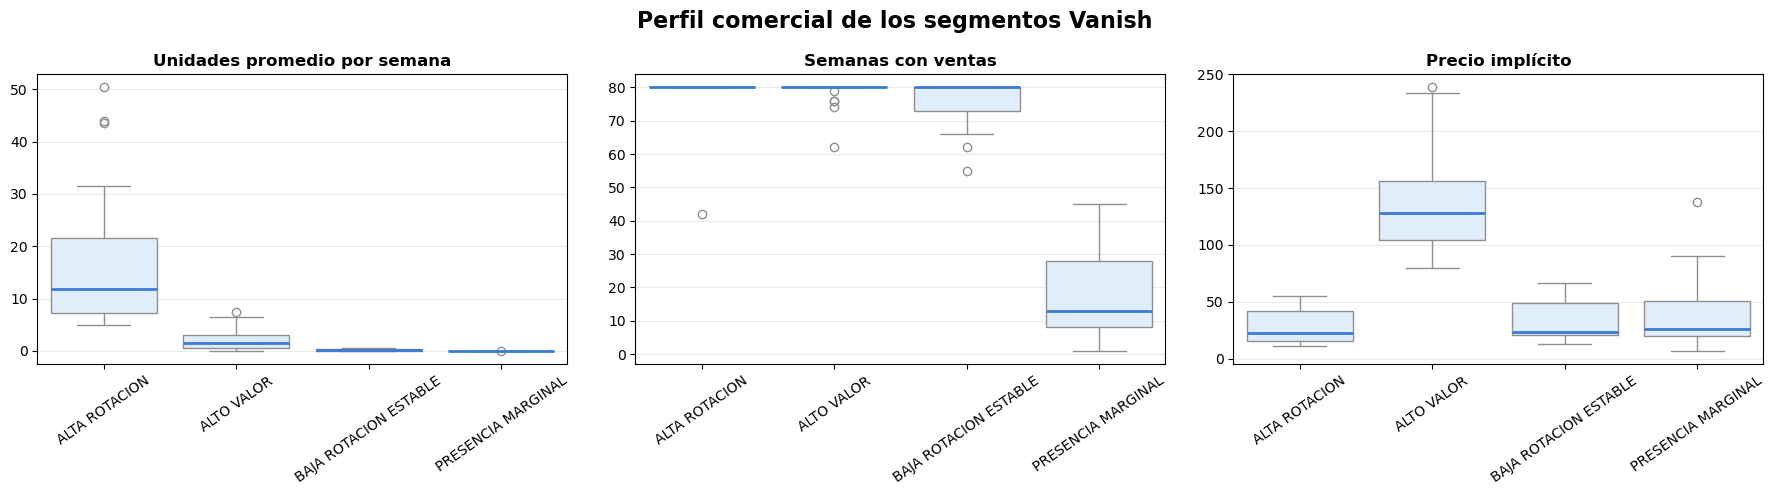

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

orden_segmentos = ["ALTA ROTACION", "ALTO VALOR", "BAJA ROTACION ESTABLE", "PRESENCIA MARGINAL"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

variables_visualizacion = [("UNIDADES_PROMEDIO_SEMANA", "Unidades promedio por semana"),  ("SEMANAS_CON_VENTAS", "Semanas con ventas"),
    ("PRECIO_IMPLICITO", "Precio implícito")]

for ax, (variable, titulo) in zip(axes, variables_visualizacion):
    sns.boxplot(data=perfil_segmentado, x="SEGMENTO", y=variable, order=orden_segmentos, color="#DCEEFF",
        medianprops={"color": "#3A7BD5", "linewidth": 2}, ax=ax)

    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Perfil comercial de los segmentos Vanish", fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

La visualización confirma que los cuatro segmentos tienen perfiles comerciales coherentes:

- Alta rotación: mayor intensidad de venta; algunos productos extremos superan las 40 unidades semanales. Mantienen cobertura prácticamente completa.
- Alto valor: rotación moderada, alta continuidad y precio claramente superior. La mediana ronda 128.
- Baja rotación estable: ventas reducidas, pero presencia sostenida durante casi todo el periodo.
- Presencia marginal: unidades casi nulas y cobertura muy inferior; el precio es variable y existe un producto atípico cercano a 140.

Un matiz importante: el precio elevado aislado del segmento marginal no lo convierte en “alto valor”. Su baja continuidad y sus ventas prácticamente inexistentes determinan su perfil. El clustering evalúa las tres variables en conjunto.

In [37]:
from sklearn.metrics import silhouette_samples

# Silueta individual de cada producto.

perfil_segmentado["SILUETA_INDIVIDUAL"] = silhouette_samples(X_escalado, etiquetas_finales)

# Resumen por segmento.

resumen_silueta = (perfil_segmentado.groupby("SEGMENTO")["SILUETA_INDIVIDUAL"].agg(PRODUCTOS="count",  SILUETA_MEDIA="mean",  
                                                                                   SILUETA_MEDIANA="median",SILUETA_MINIMA="min",
        SILUETA_MAXIMA="max").reindex(orden_segmentos))

display(resumen_silueta)

print("Productos con silueta negativa:", (perfil_segmentado["SILUETA_INDIVIDUAL"] < 0).sum())

display(perfil_segmentado.loc[perfil_segmentado["SILUETA_INDIVIDUAL"] < 0,["ITEM_CODE", "ITEM_DESCRIPTION",
            "SEGMENTO", "UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", 
            "SILUETA_INDIVIDUAL"]].sort_values("SILUETA_INDIVIDUAL"))

,PRODUCTOS,SILUETA_MEDIA,SILUETA_MEDIANA,SILUETA_MINIMA,SILUETA_MAXIMA
SEGMENTO,,,,,
ALTA ROTACION,16,0.413823,0.479853,-0.008465,0.628996
ALTO VALOR,24,0.542881,0.575599,0.252416,0.685727
BAJA ROTACION ESTABLE,17,0.539398,0.670387,0.032949,0.730763
PRESENCIA MARGINAL,19,0.456952,0.508961,-0.012534,0.624125


Productos con silueta negativa: 2


,ITEM_CODE,ITEM_DESCRIPTION,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,SILUETA_INDIVIDUAL
69,7501058796950BP1,VANISHOXIACTIONROSAGELDOYPACK500ML+PLANCHYTEXB...,PRESENCIA MARGINAL,0.051689,45,37.650043,-0.012534
73,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,ALTA ROTACION,5.011613,80,53.702720,-0.008465


8.2 Análisis de atributos categóricos.

In [38]:
# Distancia de cada producto a los cuatro centroides.

distancias_centroides = pd.DataFrame(modelo_final.transform(X_escalado), index=perfil_segmentado.index,
    columns=[f"DISTANCIA_CLUSTER_{cluster}"
        for cluster in range(modelo_final.n_clusters)])

# Productos con silueta negativa.

indices_dudosos = perfil_segmentado.index[
    perfil_segmentado["SILUETA_INDIVIDUAL"] < 0]

revision_frontera = perfil_segmentado.loc[indices_dudosos,["ITEM_CODE", "ITEM_DESCRIPTION", "SEGMENTO",
        "UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "SILUETA_INDIVIDUAL"]].copy()

# Clúster más cercano y segundo más cercano según centroides.

revision_frontera["CLUSTER_MAS_CERCANO"] = (distancias_centroides.loc[indices_dudosos].to_numpy().argmin(axis=1))

revision_frontera["SEGMENTO_MAS_CERCANO"] = (revision_frontera["CLUSTER_MAS_CERCANO"].map(nombres_clusters))

orden_distancias = np.sort(distancias_centroides.loc[indices_dudosos].to_numpy(), axis=1)

revision_frontera["DISTANCIA_1"] = orden_distancias[:, 0]
revision_frontera["DISTANCIA_2"] = orden_distancias[:, 1]

revision_frontera["MARGEN_ENTRE_CENTROIDES"] = (revision_frontera["DISTANCIA_2"] - revision_frontera["DISTANCIA_1"])

display(revision_frontera)

print("\nDistancias completas a los centroides:")
display(distancias_centroides.loc[indices_dudosos].rename(
        columns={f"DISTANCIA_CLUSTER_{cluster}": nombres_clusters[cluster]
            for cluster in nombres_clusters}))

,ITEM_CODE,ITEM_DESCRIPTION,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,SILUETA_INDIVIDUAL,CLUSTER_MAS_CERCANO,SEGMENTO_MAS_CERCANO,DISTANCIA_1,DISTANCIA_2,MARGEN_ENTRE_CENTROIDES
69,7501058796950BP1,VANISHOXIACTIONROSAGELDOYPACK500ML+PLANCHYTEXB...,PRESENCIA MARGINAL,0.051689,45,37.650043,-0.012534,3,PRESENCIA MARGINAL,1.009975,1.157957,0.147982
73,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,ALTA ROTACION,5.011613,80,53.702720,-0.008465,2,ALTA ROTACION,1.190202,1.293313,0.103111



Distancias completas a los centroides:


,ALTO VALOR,BAJA ROTACION ESTABLE,ALTA ROTACION,PRESENCIA MARGINAL
69,2.046979,1.157957,2.713810,1.009975
73,1.293313,1.617955,1.190202,2.852627


La revisión confirma que K-Means asignó correctamente ambos productos al centroide más cercano, aunque son casos fronterizos.

- Índice 69 — Presencia marginal
- Distancia a Presencia marginal: 1.0100
- Segunda opción, Baja rotación estable: 1.1580
- Margen: 0.1480
- Su cobertura de 45 semanas lo acerca a Baja rotación estable, pero su bajísima intensidad de venta (0.052) lo mantiene más próximo a - Presencia marginal.
- Índice 73 — Alta rotación
- Distancia a Alta rotación: 1.1902
- Segunda opción, Alto valor: 1.2933
- Margen: 0.1031
- Su continuidad completa y sus 5.012 unidades semanales respaldan Alta rotación, aunque el precio y su posición global lo aproximan al perfil de Alto valor.

La silueta negativa y la distancia al centroide no se contradicen:

K-Means asigna según el centroide más cercano.
La silueta compara cada producto con todos los productos de su segmento y del segmento vecino.

Por tanto, no se debe reasignar manualmente. La conclusión correcta es que 74 productos presentan una clasificación consistente y 2 deben interpretarse como productos fronterizos.

In [39]:
# Identificación de productos fronterizos.

perfil_segmentado["CLASIFICACION"] = np.where(perfil_segmentado["SILUETA_INDIVIDUAL"] < 0, "FRONTERIZO", "CONSISTENTE")

print("Estado de las asignaciones:")
display(perfil_segmentado["CLASIFICACION"].value_counts().rename_axis("CLASIFICACION").reset_index(name="PRODUCTOS"))

print("\nProductos fronterizos:")
display(perfil_segmentado.loc[perfil_segmentado["CLASIFICACION"] == "FRONTERIZO",["ITEM_CODE", "ITEM_DESCRIPTION",
            "SEGMENTO", "UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "SILUETA_INDIVIDUAL"]])

Estado de las asignaciones:


,CLASIFICACION,PRODUCTOS
0,CONSISTENTE,74
1,FRONTERIZO,2



Productos fronterizos:


,ITEM_CODE,ITEM_DESCRIPTION,SEGMENTO,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,SILUETA_INDIVIDUAL
69,7501058796950BP1,VANISHOXIACTIONROSAGELDOYPACK500ML+PLANCHYTEXB...,PRESENCIA MARGINAL,0.051689,45,37.650043,-0.012534
73,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,ALTA ROTACION,5.011613,80,53.702720,-0.008465


8.3 Visualización mediante PCA.

In [40]:
# Visualización bidimensional mediante PCA. PCA no modificará los clústeres; 
# solo proyectará las tres variables estandarizadas para observar su separación.

from sklearn.decomposition import PCA

# Reducción a dos componentes exclusivamente para visualización.

pca = PCA(n_components=2)

componentes_pca = pca.fit_transform(X_escalado)

perfil_segmentado["PC1"] = componentes_pca[:, 0]
perfil_segmentado["PC2"] = componentes_pca[:, 1]

print("Varianza explicada por cada componente:")

for numero, varianza in enumerate(
    pca.explained_variance_ratio_,start=1):
    print(f"PC{numero}: {varianza:.4f}")

print("Varianza explicada acumulada:",f"{pca.explained_variance_ratio_.sum():.4f}")

# Aportes de las variables a cada componente.
cargas_pca = pd.DataFrame(pca.components_.T, index=variables_transformadas, columns=["PC1", "PC2"])

print("\nCargas de las variables:")
display(cargas_pca)

Varianza explicada por cada componente:
PC1: 0.5084
PC2: 0.3620
Varianza explicada acumulada: 0.8704

Cargas de las variables:


,PC1,PC2
LOG_UNIDADES_PROMEDIO_SEMANA,0.624726,-0.490432
SEMANAS_CON_VENTAS,0.729962,0.090507
LOG_PRECIO_IMPLICITO,0.277259,0.866767


El PCA conserva el 87.04 % de la variabilidad, suficiente para representar visualmente la segmentación sin perder demasiada información:

PC1 explica 50.84 %. Está definido principalmente por:

- continuidad: 0.7300;
- intensidad de venta: 0.6247;
- precio, con menor influencia: 0.2773.

Por tanto, PC1 representa principalmente la fortaleza comercial, combinando rotación y permanencia.

PC2 explica 36.20 %. Está dominado por:

- precio implícito: 0.8668;
- intensidad de venta en sentido contrario: -0.4904;
- continuidad con influencia mínima: 0.0905.

PC2 separa principalmente los productos por posicionamiento económico: precios altos frente a mayor rotación.

La lectura conjunta es coherente con los segmentos: PC1 debería separar los productos activos de los marginales, mientras PC2 distinguirá especialmente ALTO VALOR de ALTA ROTACIÓN.

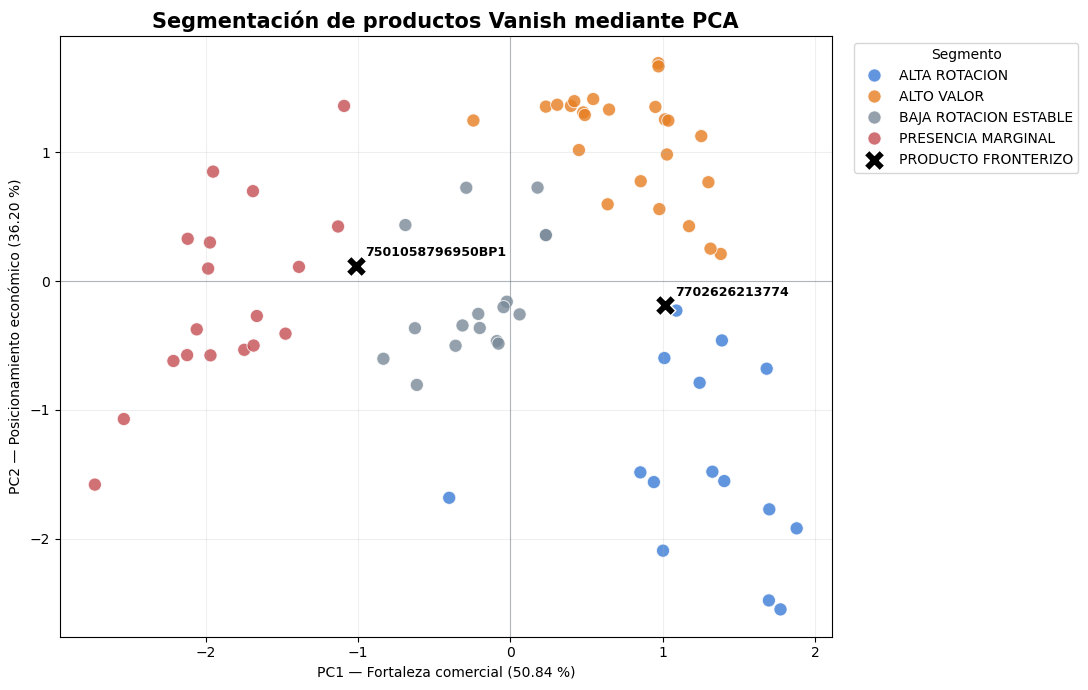

In [41]:
# Proyección y destacado de los dos productos fronterizos:

# Paleta fija para los segmentos.

colores_segmentos = {"ALTA ROTACION": "#3A7BD5", "ALTO VALOR": "#E67E22", "BAJA ROTACION ESTABLE": "#7A8A99", 
                     "PRESENCIA MARGINAL": "#C44E52"}

plt.figure(figsize=(11, 7))

# Productos con clasificación consistente.

sns.scatterplot(data=perfil_segmentado[perfil_segmentado["CLASIFICACION"] == "CONSISTENTE"],
    x="PC1", y="PC2", hue="SEGMENTO", hue_order=orden_segmentos, palette=colores_segmentos, s=90,
    alpha=0.80, edgecolor="white", linewidth=0.7)

# Productos fronterizos.

fronterizos = perfil_segmentado[perfil_segmentado["CLASIFICACION"] == "FRONTERIZO"]

plt.scatter(fronterizos["PC1"], fronterizos["PC2"], marker="X", s=220, color="black",
    edgecolor="white", linewidth=1, label="PRODUCTO FRONTERIZO", zorder=5)

# Etiquetas de los productos fronterizos.

for indice, fila in fronterizos.iterrows():
    plt.annotate(str(fila["ITEM_CODE"]), xy=(fila["PC1"], fila["PC2"]), xytext=(7, 7), textcoords="offset points",
        fontsize=9, fontweight="bold")

plt.axhline(0, color="#6E7A89", linewidth=0.8, alpha=0.5)
plt.axvline(0, color="#6E7A89", linewidth=0.8, alpha=0.5)

plt.title("Segmentación de productos Vanish mediante PCA", fontsize=15, fontweight="bold")
plt.xlabel("PC1 — Fortaleza comercial (50.84 %)")
plt.ylabel("PC2 — Posicionamiento económico (36.20 %)")
plt.grid(alpha=0.20)
plt.legend(title="Segmento", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

<b>Conclusión gráfico.</b>

La proyección mediante PCA conserva el 87.04 % de la variabilidad de las tres variables utilizadas por K-Means. La primera componente representa principalmente la fortaleza comercial, mientras que la segunda diferencia el posicionamiento económico de los productos. La distribución muestra una separación coherente entre los segmentos: los productos de presencia marginal se concentran en la zona de menor fortaleza comercial; los de alto valor ocupan posiciones elevadas por su mayor precio; y los de alta rotación se sitúan principalmente en la zona de mayor fortaleza y menor posicionamiento económico relativo. Los dos productos con silueta negativa aparecen cerca de los límites entre segmentos, lo que respalda su identificación como casos fronterizos y no como errores generales del modelo.

9. Recomendaciones y conclusiones.

La segmentación obtenida mediante K-Means permite diferenciar cuatro comportamientos comerciales. Estas categorías sirven para orientar la revisión del portafolio, pero no constituyen por sí solas una decisión definitiva sobre cada producto.

Alta rotación

Este segmento concentra el 84.4 % de las unidades y el 50.8 % del valor vendido. Representa el principal motor de volumen del portafolio.

**Líneas de acción:**

- asegurar disponibilidad e inventario suficiente;
- reducir el riesgo de faltantes;
- priorizar su presencia en los canales de mayor demanda;
- analizar oportunidades de venta cruzada;
- revisar individualmente los productos de rotación excepcionalmente alta.

Alto valor

Este grupo genera el 48.2 % del valor con solo el 14.4 % de las unidades. Su aportación depende principalmente de precios implícitos elevados y de una presencia comercial sostenida.

**Líneas de acción:**

- proteger su posicionamiento y disponibilidad;
- vigilar posibles variaciones de precio;
- evaluar márgenes y rentabilidad real;
- identificar los canales y clientes que explican su valor;
- evitar promociones que reduzcan innecesariamente su contribución económica.

Baja rotación estable

Los productos permanecen activos durante casi todo el periodo, pero aportan aproximadamente el 1 % del valor y el 1.2 % de las unidades.

**Líneas de acción:**

- revisar si cumplen una función estratégica dentro del portafolio;
- comprobar si complementan otros productos;
- analizar su rentabilidad después de costos logísticos y de inventario;
- evaluar promociones o ajustes de presentación;
- considerar una prueba controlada antes de modificar su continuidad.

Presencia marginal

Este segmento presenta ventas prácticamente nulas y una continuidad comercial reducida. Puede incluir lanzamientos, promociones, productos discontinuados o registros con disponibilidad limitada.

**Líneas de acción:**

- verificar la fecha de incorporación y retiro de cada producto;
- comprobar problemas de inventario o distribución;
- distinguir productos promocionales de referencias permanentes;
- revisar posibles inconsistencias en el registro de ventas;
- evaluar su continuidad únicamente después de conocer estas causas.

In [42]:
recomendaciones_segmentos = pd.DataFrame({"SEGMENTO": ["ALTA ROTACION", "ALTO VALOR",
        "BAJA ROTACION ESTABLE", "PRESENCIA MARGINAL"],
        "HALLAZGO_PRINCIPAL": ["Concentra la mayor parte de las unidades vendidas",
        "Genera alto valor con menor volumen de unidades", "Mantiene continuidad, pero presenta demanda reducida",
        "Registra ventas mínimas y baja continuidad"],
        "ACCION_PROPUESTA": ["Proteger disponibilidad y prevenir faltantes", "Proteger posicionamiento y revisar rentabilidad",
        "Evaluar función estratégica y costos de permanencia", "Investigar causas antes de decidir su continuidad"],
        "VALIDACION_REQUERIDA": ["Inventario, faltantes, margen y demanda por canal", "Margen, promociones, clientes y evolución del precio",
        "Margen, costos logísticos, complementariedad y stock", "Fecha de alta, disponibilidad, promociones y descontinuación"]})

display(recomendaciones_segmentos)

,SEGMENTO,HALLAZGO_PRINCIPAL,ACCION_PROPUESTA,VALIDACION_REQUERIDA
0,ALTA ROTACION,Concentra la mayor parte de las unidades vendidas,Proteger disponibilidad y prevenir faltantes,"Inventario, faltantes, margen y demanda por canal"
1,ALTO VALOR,Genera alto valor con menor volumen de unidades,Proteger posicionamiento y revisar rentabilidad,"Margen, promociones, clientes y evolución del ..."
2,BAJA ROTACION ESTABLE,"Mantiene continuidad, pero presenta demanda re...",Evaluar función estratégica y costos de perman...,"Margen, costos logísticos, complementariedad y..."
3,PRESENCIA MARGINAL,Registra ventas mínimas y baja continuidad,Investigar causas antes de decidir su continuidad,"Fecha de alta, disponibilidad, promociones y d..."


Conclusiones

El análisis permitió segmentar 76 productos Vanish en cuatro grupos con comportamientos comerciales diferenciados. La elección de cuatro clústeres se sustentó en el coeficiente de silueta, la inercia, la distribución de productos y la utilidad comercial de la segmentación.

El modelo final obtuvo un coeficiente de silueta de 0.4934. Aunque la separación no es absoluta, los perfiles resultaron consistentes y comercialmente interpretables:

- **Alta rotación:** concentra el 84.4 % de las unidades y el 50.8 % del valor vendido.
- **Alto valor:** aporta el 48.2 % del valor con solo el 14.4 % de las unidades.
- **Baja rotación estable:** mantiene continuidad durante el periodo, pero presenta una demanda reducida.
- **Presencia marginal:** registra ventas mínimas y una menor permanencia comercial.

Los segmentos de alta rotación y alto valor reúnen 40 de los 76 productos y generan aproximadamente el 99 % del valor vendido. Esta concentración permite identificar los productos que sostienen el desempeño del portafolio, pero no implica que los demás deban eliminarse.

La revisión de las siluetas individuales mostró 74 asignaciones consistentes y únicamente 2 productos fronterizos. Ambos permanecieron correctamente vinculados al centroide más cercano, aunque su clasificación debe interpretarse con cautela.

La proyección mediante PCA conservó el 87.04 % de la variabilidad. La primera componente representó principalmente la fortaleza comercial, mientras que la segunda diferenció el posicionamiento económico. La visualización confirmó la coherencia general de los cuatro segmentos.

Las variables categóricas disponibles no explicaron la segmentación. CATEGORY y ATTR2 fueron constantes; ATTR1 presentó solo dos casos excepcionales; y la prueba chi-cuadrado no encontró asociación entre ATTR3 y los segmentos (p = 0.8626; V de Cramér = 0.0990). Por tanto, los grupos están definidos principalmente por la rotación, la continuidad y el precio implícito.

Alcance de las recomendaciones

El modelo identifica patrones de comportamiento, pero no determina por sí solo la continuidad, rentabilidad o relevancia estratégica de cada producto. Antes de tomar decisiones sobre el portafolio se requiere incorporar información de margen, costos logísticos, inventario, disponibilidad, promociones, canales, clientes y fechas de incorporación o retiro.

En consecuencia, la segmentación debe utilizarse como una herramienta de priorización para investigar y decidir, no como un mecanismo automático de eliminación de productos.

10. Resultados finales y exportación.

In [43]:
# Selección de columnas para la entrega final.

columnas_resultado = ["ITEM_CODE", "ITEM_DESCRIPTION", "CATEGORY", "FORMAT", "ATTR1", "ATTR2", "ATTR3",
    "UNIDADES_PROMEDIO_SEMANA", "SEMANAS_CON_VENTAS", "PRECIO_IMPLICITO", "VENTAS_UNIDADES", "VENTAS_VALOR",
    "CLUSTER", "SEGMENTO", "SILUETA_INDIVIDUAL", "CLASIFICACION"]

resultado_segmentacion = (perfil_segmentado[columnas_resultado].sort_values(by=["SEGMENTO", "VENTAS_VALOR"],
        ascending=[True, False]).reset_index(drop=True))

print("Dimensiones de la tabla final:", resultado_segmentacion.shape)
print("Productos únicos:", resultado_segmentacion["ITEM_CODE"].nunique())

display(resultado_segmentacion.head(10))

Dimensiones de la tabla final: (76, 16)
Productos únicos: 76


,ITEM_CODE,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,UNIDADES_PROMEDIO_SEMANA,SEMANAS_CON_VENTAS,PRECIO_IMPLICITO,VENTAS_UNIDADES,VENTAS_VALOR,CLUSTER,SEGMENTO,SILUETA_INDIVIDUAL,CLASIFICACION
0,7503002319529,VANISH LIQUIDO BOTELLA 925ML NAL. 7503002319529,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,18.360625,80,55.180233,1468.850,81051.485,2,ALTA ROTACION,0.395093,CONSISTENTE
1,7501058717023,VANISH ROSA QUITAMANCHAS GEL MULTIUSOS POUCH 4...,1,GEL,SAFE BLEACH,FABRIC TREATMENT,ROSA,43.900562,80,22.597337,3512.045,79362.863,2,ALTA ROTACION,0.600070,CONSISTENTE
2,7501058717030,VANISH CRYSTAL WHITE QUITAMANCHAS GEL POUCH 45...,1,GEL,SAFE BLEACH,FABRIC TREATMENT,BLANCO,31.541150,80,22.716824,2523.292,57321.180,2,ALTA ROTACION,0.625631,CONSISTENTE
3,7501058714596,VANISH SUPER BARRA QUITA MANCHAS 68GR 75010587...,1,BARRA,SAFE BLEACH,FABRIC TREATMENT,ROSA,50.374962,80,12.342930,4029.997,49741.969,2,ALTA ROTACION,0.556499,CONSISTENTE
4,7501058751195,VANISH WHITE BOTELLA 900 ML 7501058751195,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,BLANCO,10.546188,80,54.657306,843.695,46114.096,2,ALTA ROTACION,0.301264,CONSISTENTE
5,7891035040276,VANISH SUPER BARRA WHITE QUITA MANCHAS 68GR 78...,1,BARRA,SAFE BLEACH,FABRIC TREATMENT,BLANCO,43.676012,80,12.447585,3494.081,43492.871,2,ALTA ROTACION,0.566542,CONSISTENTE
6,7501058753458,VANISH PODER O2 CRYSTAL WHITE DOYPACK 120 GR 7...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,BLANCO,18.361900,80,22.470867,1468.952,33008.625,2,ALTA ROTACION,0.628996,CONSISTENTE
7,7501058757548,VANISH ROSA COLOR LIQ. DOYPACK 650ML NAL 75010...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA,9.889650,80,38.035225,791.172,30092.405,2,ALTA ROTACION,0.482049,CONSISTENTE
8,7501058753441,VANISH PODER O2 DOYPACK 120 GR 7501058753441,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,15.771562,80,22.683842,1261.725,28620.771,2,ALTA ROTACION,0.617448,CONSISTENTE
9,7702626213781,VANISH OXI ACTION CRISTAL WHITE DOYPACK 240 GR...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,BLANCO,5.802112,80,54.523174,464.169,25307.967,2,ALTA ROTACION,0.059551,CONSISTENTE


In [44]:
# Validaciones finales de integridad.

validaciones_finales = pd.Series({
    "FILAS_RESULTADO": len(resultado_segmentacion),
    "PRODUCTOS_UNICOS": (resultado_segmentacion["ITEM_CODE"].nunique()),
    "DUPLICADOS_ITEM_CODE": (resultado_segmentacion["ITEM_CODE"].duplicated().sum()),
    "SEGMENTOS_FALTANTES": (resultado_segmentacion["SEGMENTO"].isna().sum()),
    "CLASIFICACIONES_FALTANTES": (resultado_segmentacion["CLASIFICACION"].isna().sum()),
    "SILUETAS_FALTANTES": (resultado_segmentacion["SILUETA_INDIVIDUAL"].isna().sum()),
    "PRODUCTOS_CONSISTENTES": (resultado_segmentacion["CLASIFICACION"].eq("CONSISTENTE").sum()),
    "PRODUCTOS_FRONTERIZOS": (resultado_segmentacion["CLASIFICACION"].eq("FRONTERIZO").sum())})

display(validaciones_finales.rename_axis("VALIDACION").reset_index(name="RESULTADO"))

,VALIDACION,RESULTADO
0,FILAS_RESULTADO,76
1,PRODUCTOS_UNICOS,76
2,DUPLICADOS_ITEM_CODE,0
3,SEGMENTOS_FALTANTES,0
4,CLASIFICACIONES_FALTANTES,0
5,SILUETAS_FALTANTES,0
6,PRODUCTOS_CONSISTENTES,74
7,PRODUCTOS_FRONTERIZOS,2


In [45]:
# Exportación de la segmentación final.

nombre_archivo = "segmentacion_productos_vanish.xlsx"

with pd.ExcelWriter(nombre_archivo, engine="openpyxl") as writer:
    resultado_segmentacion.to_excel(writer, sheet_name="Productos segmentados", index=False)
    
    resumen_clusters.to_excel(writer, sheet_name="Resumen segmentos", index=False)
    
    recomendaciones_segmentos.to_excel(writer, sheet_name="Recomendaciones", index=False)

print(f"Archivo exportado correctamente: {nombre_archivo}")

Archivo exportado correctamente: segmentacion_productos_vanish.xlsx
